# Praktikum Machine Learning — Student Performance

Notebook ini memuat alur Data Loading, Data Cleaning, EDA, Data Processing, Data Splitting, serta contoh model prediksi nilai akhir siswa.

## 1. Import Library dan Data Loading
Dataset `student-mat.csv` harus berada di folder yang sama dengan notebook. File menggunakan pemisah titik koma (`;`).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('student-mat.csv', sep=';')

print('Ukuran dataset:', df.shape)
display(df.head())

Ukuran dataset: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [2]:
# Melihat tipe data dan jumlah data pada setiap kolom
df.info()

# Melihat nama kolom
print(df.columns.tolist())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

## 2. Data Cleaning
Periksa nilai kosong dan baris duplikat terlebih dahulu. Jangan menghapus data hanya karena terdeteksi sebagai outlier tanpa alasan yang jelas; nilai seperti absensi tinggi bisa saja merupakan data yang valid.

In [3]:
# Jumlah nilai kosong pada setiap kolom
print(df.isnull().sum())

# Jumlah baris duplikat
print('Jumlah baris duplikat:', df.duplicated().sum())

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64
Jumlah baris duplikat: 0


In [4]:
# Hapus duplikat hanya jika memang ditemukan
df = df.drop_duplicates().copy()

# Jika ada nilai kosong, tampilkan jumlahnya kembali
print('Ukuran data setelah pemeriksaan duplikasi:', df.shape)
print('Total nilai kosong:', df.isnull().sum().sum())

Ukuran data setelah pemeriksaan duplikasi: (395, 33)
Total nilai kosong: 0


## 3. Exploratory Data Analysis (EDA)
Gunakan statistik deskriptif dan grafik untuk memahami data sebelum membangun model.

In [12]:
display(df.describe())

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


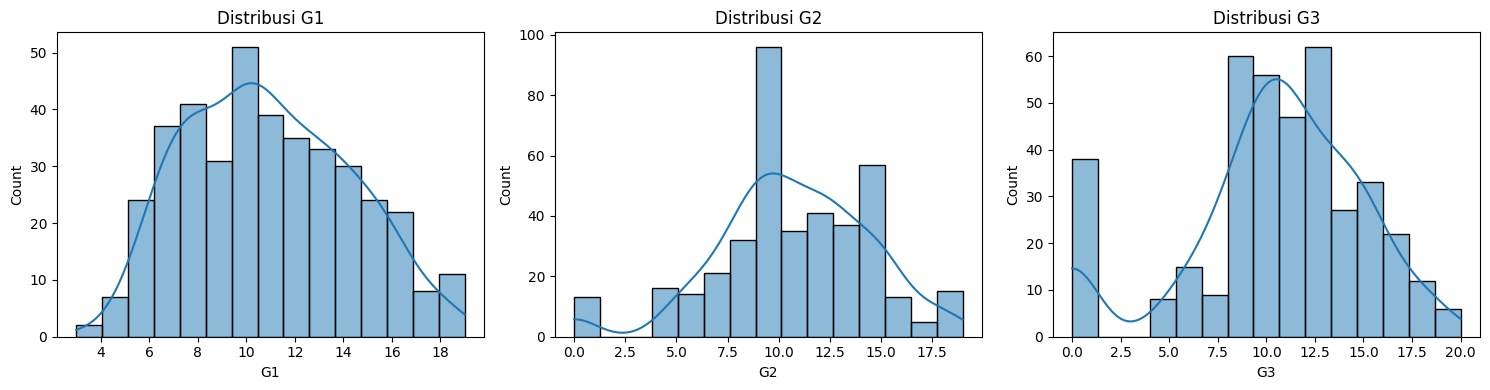

In [5]:
# Statistik deskriptif kolom numerik
display(df.describe())

# Distribusi nilai G1, G2, dan G3
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['G1', 'G2', 'G3']):
    sns.histplot(data=df, x=col, bins=15, kde=True, ax=ax)
    ax.set_title(f'Distribusi {col}')
plt.tight_layout()
plt.show()

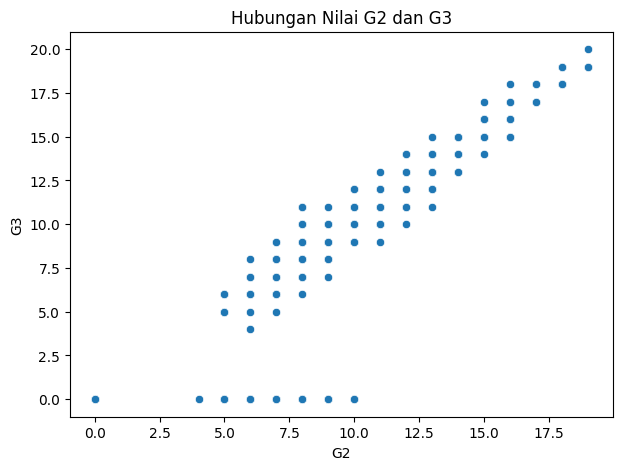

In [6]:
# Hubungan nilai periode pertama, kedua, dan nilai akhir
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x='G2', y='G3')
plt.title('Hubungan Nilai G2 dan G3')
plt.show()

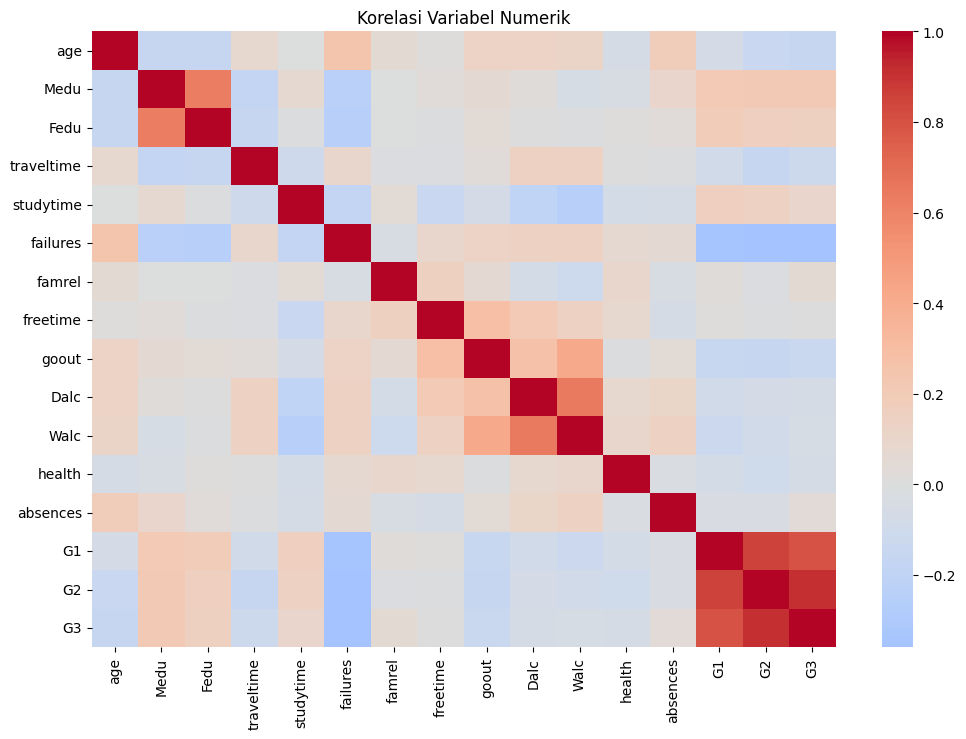

In [7]:
# Korelasi antar kolom numerik
numeric_df = df.select_dtypes(include='number')
plt.figure(figsize=(12, 8))
sns.heatmap(numeric_df.corr(), cmap='coolwarm', center=0)
plt.title('Korelasi Variabel Numerik')
plt.show()

## 4. Data Processing


In [8]:
# Memisahkan fitur (X) dan target (y)
X = df.drop(columns=['G3'])
y = df['G3']

numeric_features = X.select_dtypes(include=['number']).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

print('Jumlah fitur numerik:', len(numeric_features))
print('Jumlah fitur kategorikal:', len(categorical_features))

Jumlah fitur numerik: 15
Jumlah fitur kategorikal: 17


## 5. Data Splitting
Dataset dibagi menjadi 80% data latih dan 20% data uji. `random_state=42` digunakan agar pembagian dapat diulang dengan hasil yang sama.

In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print('Jumlah data awal:', len(df))
print('Jumlah data latih:', len(X_train))
print('Jumlah data uji:', len(X_test))

Jumlah data awal: 395
Jumlah data latih: 316
Jumlah data uji: 79


## 6. Contoh Pemodelan dan Evaluasi (opsional/pengembangan)
Linear Regression digunakan sebagai contoh model untuk memprediksi nilai numerik `G3`. Hasil evaluasi yang muncul setelah menjalankan notebook dapat dicantumkan ke laporan.

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Preprocessing numerik dan kategorikal
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print('MAE:', round(mean_absolute_error(y_test, y_pred), 3))
print('RMSE:', round(np.sqrt(mean_squared_error(y_test, y_pred)), 3))
print('R2:', round(r2_score(y_test, y_pred), 3))

MAE: 1.647
RMSE: 2.378
R2: 0.724


In [11]:
# Membandingkan sebagian nilai aktual dan prediksi
hasil_prediksi = pd.DataFrame({
    'Nilai Aktual G3': y_test,
    'Prediksi G3': np.round(y_pred, 2)
})
display(hasil_prediksi.head(10))

,Nilai Aktual G3,Prediksi G3
78,10,6.00
371,12,11.53
248,5,2.87
55,10,8.80
390,9,8.55
223,13,11.89
42,18,19.10
234,6,7.17
316,0,7.41
116,14,12.31
